# DWD-Wetterdaten Berlin: 2020 bis heute

Dieses Notebook ist die Grundlage für eine spätere Auswertung der täglichen DWD-Wetterwerte. Die CSV enthält Tagesminimum, Tagesmaximum, Tagesmitteltemperatur, Niederschlagsmenge und Sonnenscheindauer für die DWD-Station **Berlin-Dahlem (FU), Stations-ID 00403**.

Der verfügbare Zeitraum ist **01.01.2020 bis 01.11.2026**. Der DWD veröffentlicht die Tageswerte üblicherweise bis zum Vortag; deshalb ist der 01.11.2026 der letzte verfügbare Tag, obwohl das heutige Datum der 02.11.2026 ist.

## Verfügbarkeit der benötigten Werte

Geprüft wurden tägliche Minimum-, Maximum- und Mitteltemperatur, Niederschlag und Sonnenscheindauer (`TNK`, `TXK`, `TMK`, `RSK`, `SDK`). Insgesamt umfasst der Zeitraum 2.497 Kalendertage.

| DWD-Station | Temperaturwerte | Niederschlag | Sonnenschein | Einschätzung |
| --- | ---: | ---: | ---: | --- |
| 00400 Berlin-Buch | 2.497/2.497 | 2.497/2.497 | 0/2.497 | Keine Sonnenscheindaten |
| 00403 Berlin-Dahlem (FU) | 2.481/2.497 | 2.482/2.497 | 2.481/2.497 | Beste Abdeckung der fünf Werte |
| 00420 Berlin-Marzahn | 1.977/2.497 | 1.977/2.497 | 0/2.497 | Unvollständige Reihe, kein Sonnenschein |
| 00427 Berlin Brandenburg | 2.497/2.497 | 2.496/2.497 | 1.924/2.497 | Sonnenschein lückenhaft |
| 00433 Berlin-Tempelhof | 2.497/2.497 | 2.486/2.497 | 984/2.497 | Sonnenschein ab 2025 nicht verfügbar |

Daher wird Berlin-Dahlem (FU) verwendet. Dort sind 2020 bis 2024 und der Zeitraum bis 01.11.2026 für alle fünf Werte vollständig. Im Jahr 2025 liegen für 349 von 365 Tagen alle fünf Werte vor; an den übrigen Tagen fehlen Werte. Fehlende Messwerte bleiben in der CSV leer und werden nicht geschätzt.

## CSV-Datei und Spalten

Die Datei `berlin_dwd_tageswerte_2020_bis_2026-11-01.csv` liegt im selben Ordner wie dieses Notebook. Sie enthält eine Zeile pro Kalendertag; fehlende Werte sind leere Felder.

- `temp_min_c`: Tagesminimum der Lufttemperatur in °C (`TNK`)
- `temp_max_c`: Tagesmaximum der Lufttemperatur in °C (`TXK`)
- `temp_durchschnitt_c`: Tagesmitteltemperatur in °C (`TMK`)
- `niederschlagsmenge_mm`: Niederschlagsmenge pro Tag in mm (`RSK`)
- `sonnenstunden`: Sonnenscheindauer pro Tag in Stunden (`SDK`)

Datenquelle: [DWD Climate Data Center, tägliche Klimawerte](https://opendata.dwd.de/climate_environment/CDC/observations_germany/climate/daily/kl/).

In [2]:
import csv
from pathlib import Path

csv_pfad = Path("berlin_dwd_tageswerte_2020_bis_2026-11-01.csv")
with csv_pfad.open(encoding="utf-8", newline="") as datei:
    wetterdaten = list(csv.DictReader(datei))

print(f"CSV geladen: {len(wetterdaten)} Tageszeilen")
print("Spalten:", ", ".join(wetterdaten[0].keys()))

CSV geladen: 2497 Tageszeilen
Spalten: datum, stations_id, temp_min_c, temp_max_c, temp_durchschnitt_c, niederschlagsmenge_mm, sonnenstunden


## Tagesmitteltemperatur im Jahresverlauf

Jede Linie zeigt die täglichen Mitteltemperaturen eines Jahres. Die x-Achse richtet alle Jahre am selben Monatstag aus; dadurch lassen sich saisonale Verläufe vergleichen. Fehlende Messwerte werden als Unterbrechungen dargestellt. 2026 endet die Linie am letzten verfügbaren DWD-Datum.

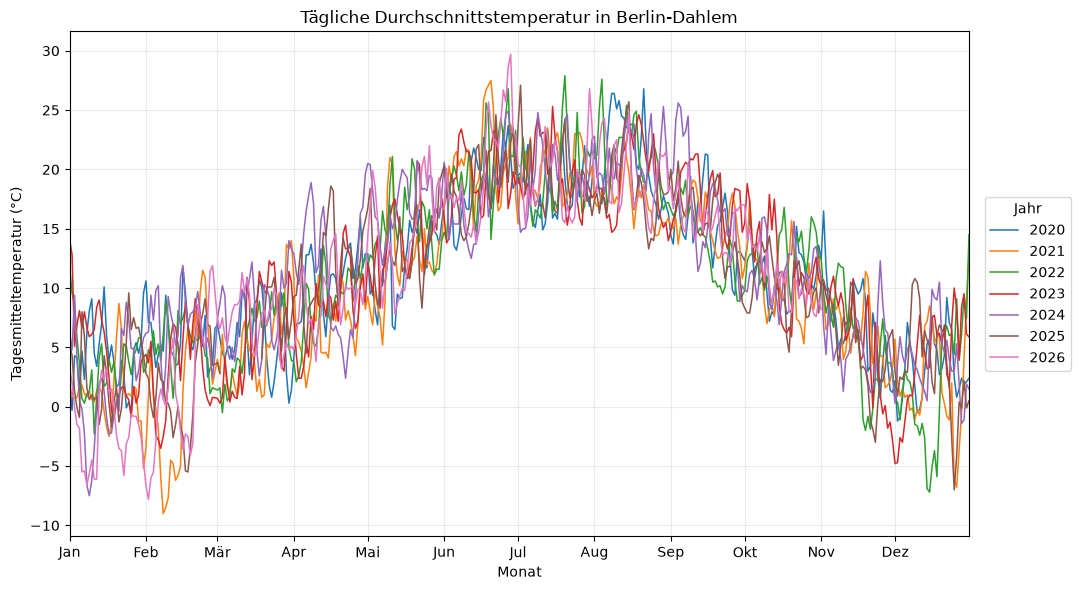

In [2]:
from datetime import datetime
import math
import matplotlib.pyplot as plt

jahre = sorted({zeile["datum"][:4] for zeile in wetterdaten})
monate = ["Jan", "Feb", "Mär", "Apr", "Mai", "Jun", "Jul", "Aug", "Sep", "Okt", "Nov", "Dez"]
x_ticks = [datetime(2000, monat, 1) for monat in range(1, 13)]
farben = plt.colormaps["tab10"]

fig, ax = plt.subplots(figsize=(13, 6))
for index, jahr in enumerate(jahre):
    jahreszeilen = [zeile for zeile in wetterdaten if zeile["datum"].startswith(jahr)]
    x_werte = [datetime.strptime("2000-" + zeile["datum"][5:], "%Y-%m-%d") for zeile in jahreszeilen]
    y_werte = [
        float(zeile["temp_durchschnitt_c"]) if zeile["temp_durchschnitt_c"] else math.nan
        for zeile in jahreszeilen
    ]
    ax.plot(x_werte, y_werte, label=jahr, color=farben(index), linewidth=1.1)

ax.set_title("Tägliche Durchschnittstemperatur in Berlin-Dahlem")
ax.set_xlabel("Monat")
ax.set_ylabel("Tagesmitteltemperatur (°C)")
ax.set_xticks(x_ticks, monate)
ax.set_xlim(datetime(2000, 1, 1), datetime(2000, 12, 31))
ax.grid(True, alpha=0.25)
ax.legend(title="Jahr", loc="center left", bbox_to_anchor=(1.01, 0.5))
fig.tight_layout(rect=(0, 0, 0.84, 1))
plt.show()

## Weiterführende Prognose

Die eigenständige Modellierung, der Genauigkeitstest und die Tagesprognose befinden sich im separaten Notebook [berlin_dwd_temperaturprognose.ipynb](berlin_dwd_temperaturprognose.ipynb).